# 第 4 章：迴歸與分類中的線性模型

**課程：大數據分析（碩士班）**

本講義分成兩個部分，使用同一套思維：**先做好資料前處理，再比較「一般模型」、「變數選擇」、「懲罰式（Lasso）模型」**，並用**交叉驗證**公平地評估。

| 部分 | 問題類型 | 資料集 | 模型 |
|---|---|---|---|
| **Part 1** | 迴歸（預測連續數值） | 加州房價 | 線性迴歸、前向選擇（Forward Selection）、Lasso |
| **Part 2** | 分類（預測類別） | MNIST 手寫數字 | 邏輯斯迴歸、Lasso 邏輯斯迴歸 |

<table align="left">
  <td>
    <a href="https://colab.research.google.com/github/hanchen92/THU-STAT-BigData-115-1-6200/blob/main/04_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>
  </td>
  <td>
    <a target="_blank" href="https://kaggle.com/kernels/welcome?src=https://github.com/hanchen92/THU-STAT-BigData-115-1-6200/main/04_regression.ipynb"><img src="https://kaggle.com/static/images/open-in-kaggle.svg" /></a>
  </td>
</table>

## 學習目標

- 能完成一個完整的資料分析流程：**取得資料 → 切分資料 → 前處理 → 建模 → 評估**
- 理解**分層抽樣**、**遺漏值填補**、**類別變數編碼**、**特徵縮放**的目的與做法
- 學會用 `Pipeline` 與 `ColumnTransformer` 把前處理與模型串在一起，**避免資料洩漏**
- 理解並比較三種處理「變數過多」的策略：使用全部變數、前向選擇、Lasso
- 理解 **K 折交叉驗證**，並能解讀「訓練誤差」與「交叉驗證誤差」的差距
- 了解邏輯斯迴歸（含 L1 懲罰）在多類別分類的應用

> ⚠️ **閱讀提醒**：本 notebook 的程式碼必須**由上而下依序執行**，後面的 cell 會用到前面建立的變數（例如 `housing`、`X_train`、`preprocessing`）。

## 0. 載入基本套件

In [1]:
import sklearn                      # 機器學習套件 Scikit-Learn
import numpy as np                  # 數值運算
import matplotlib.pyplot as plt     # 繪圖

---
# Part 1：迴歸 —— 預測加州房價

# 1. 資料收集（Data Collection）

> *歡迎來到「機器學習房屋公司」！你的任務是：根據加州各街區（district）的特徵，預測該街區的房價中位數。*

這是一個**監督式學習**、**迴歸**問題：
- **目標變數（label）**：`median_house_value`（街區房價中位數）
- **特徵（features）**：經緯度、屋齡中位數、房間總數、人口數、家戶數、收入中位數、離海距離類別……

## 1.1 下載資料

In [2]:
from pathlib import Path
import pandas as pd
import tarfile
import urllib.request
import numpy as np


def load_housing_data():
    tarball_path = Path("datasets/housing.tgz")
    # 若本機還沒有壓縮檔，就建立資料夾、下載、再解壓縮
    if not tarball_path.is_file():
        Path("datasets").mkdir(parents=True, exist_ok=True)
        url = "https://github.com/ageron/data/raw/main/housing.tgz"
        urllib.request.urlretrieve(url, tarball_path)
        with tarfile.open(tarball_path) as housing_tarball:
            housing_tarball.extractall(path="datasets")
    return pd.read_csv(Path("datasets/housing/housing.csv"))   # 讀成 pandas DataFrame

housing_old = load_housing_data()   # 保留原始資料（房價未取對數）

In [3]:
# 額外程式碼 – 定義 save_fig()，之後可把圖表存成高解析度 PNG
IMAGES_PATH = Path() / "images" / "end_to_end_project"
IMAGES_PATH.mkdir(parents=True, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=300):
    path = IMAGES_PATH / f"{fig_id}.{fig_extension}"
    if tight_layout:
        plt.tight_layout()   # 自動調整間距
    plt.savefig(path, format=fig_extension, dpi=resolution)

### 對目標變數取對數

房價資料通常**右偏**（少數極貴的街區把平均拉高），而且誤差大小常與房價成正比。取自然對數後：

- 分布更接近對稱，較符合線性迴歸的常態誤差假設
- 模型誤差改為「**相對誤差**」（百分比）而非絕對金額

> ⚠️ 取對數之後，**模型預測值與 RMSE 都是「對數尺度」**，若要回到美元，必須用 `np.exp()` 還原（後面 3.2 節會示範）。

In [4]:
housing = housing_old.copy()                                          # 複製一份，避免動到原始資料
housing["median_house_value"] = np.log(housing_old["median_house_value"])   # 目標變數取自然對數

## 1.2 切分訓練集與測試集（Create a Test Set）

測試集代表「**未來才會看到的新資料**」，必須在一開始就切出去、鎖起來，**整個建模過程都不能偷看**（否則評估結果會過度樂觀）。

### 分層抽樣（Stratified Sampling）

隨機切分可能剛好讓測試集的收入分布偏離母體。由於**收入中位數**是預測房價最重要的特徵之一，我們先把它切成 5 個類別（`income_cat`），再按照類別比例做**分層抽樣**，讓訓練集與測試集的收入分布和整體資料一致。

| 類別 | 收入中位數範圍（單位：萬美元） |
|---|---|
| 1 | 0 ～ 1.5 |
| 2 | 1.5 ～ 3.0 |
| 3 | 3.0 ～ 4.5 |
| 4 | 4.5 ～ 6.0 |
| 5 | 6.0 以上 |

In [5]:
from sklearn.model_selection import train_test_split

# pd.cut：依照指定的切點，把連續變數切成類別
housing["income_cat"] = pd.cut(housing["median_income"],
                               bins=[0., 1.5, 3.0, 4.5, 6., np.inf],   # 切點，np.inf 代表正無窮大
                               labels=[1, 2, 3, 4, 5])                 # 各區間的類別標籤

In [6]:
# test_size=0.2：20% 當測試集；stratify：依 income_cat 的比例分層抽樣；random_state：固定亂數種子
strat_train_set, strat_test_set = train_test_split(
    housing, test_size=0.2, stratify=housing["income_cat"], random_state=42)


# income_cat 只是為了分層而建立的輔助欄位，切完後就丟掉（inplace=True：直接修改原物件）
for set_ in (strat_train_set, strat_test_set):
    set_.drop("income_cat", axis=1, inplace=True)

# 2. 資料探索與特徵工程

## 2.1 資料探索（Data Exploration）

探索時只使用**訓練集**，而且先複製一份，這樣怎麼調整都不會影響原始訓練集。

In [7]:
housing = strat_train_set.copy()   # 只用訓練集做探索

## 2.2 特徵工程（Feature Engineering）

原始特徵（如 `total_rooms`）反映的是**整個街區的總量**，街區大小不同，數字就沒有可比性。比起總量，**比率**通常更有意義：

| 新特徵 | 公式 | 意義 |
|---|---|---|
| `rooms_per_house` | 房間總數 ÷ 家戶數 | 平均每戶有幾間房 |
| `bedrooms_ratio` | 臥室總數 ÷ 房間總數 | 臥室佔房間的比例 |
| `people_per_house` | 人口數 ÷ 家戶數 | 平均每戶人數（擁擠程度） |

> 💡 這裡只是示範與探索；實際建模時，這些比率會在後面的 `ColumnTransformer` 中自動產生（見 2.5 節）。

In [8]:
housing["rooms_per_house"] = housing["total_rooms"] / housing["households"]
housing["bedrooms_ratio"] = housing["total_bedrooms"] / housing["total_rooms"]
housing["people_per_house"] = housing["population"] / housing["households"]

## 2.3 自訂轉換器（Custom Transformers）與還原訓練集

接下來要正式建立前處理流程。先**還原成原始的訓練集**，並把**特徵與目標變數分開**：

- `housing`：特徵（`X`）
- `housing_labels`：目標變數（`y`，已取對數的房價）

> `drop()` 預設會回傳「少了該欄位的新副本」，不會改動原本的 `strat_train_set`。

In [9]:
housing = strat_train_set.drop("median_house_value", axis=1)    # 特徵：丟掉目標變數那一欄
housing_labels = strat_train_set["median_house_value"].copy()   # 目標變數

下面匯入建立自訂轉換器所需的工具（`FunctionTransformer` 可以把任何函數包成 Scikit-Learn 的轉換器，後面會用到；其餘幾個匯入在本講義中沒有實際使用）：

In [10]:
from sklearn.preprocessing import FunctionTransformer       # 把任意函數包成轉換器
from sklearn.metrics.pairwise import rbf_kernel             # （本講義未使用）
from sklearn.base import BaseEstimator, TransformerMixin    # （本講義未使用）自訂轉換器類別的基底
from sklearn.utils.validation import check_array, check_is_fitted   # （本講義未使用）

## 2.4 資料清理（Data Cleaning）

### 遺漏值（Missing Data）

資料中的 `total_bedrooms` 有遺漏值，而大多數機器學習演算法無法處理 `NaN`。常見的三種做法：

1. 刪除有遺漏值的**列**（損失樣本）
2. 刪除有遺漏值的**欄**（損失特徵）
3. **填補**遺漏值（0、平均數、**中位數**…）

這裡採用**選項 3：以中位數填補**（對離群值較穩健）。

> ⚠️ **重點**：中位數必須**只由訓練集計算**，並用同一個值去填補驗證集與測試集。`SimpleImputer` 的 `fit()` 負責「學習」中位數，`transform()` 負責「套用」，這種「先 fit、再 transform」的設計正是為了避免資料洩漏。

In [11]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")                    # 以中位數填補
housing_num = housing.select_dtypes(include=[np.number])      # 只取數值欄位（類別欄位不能算中位數）
imputer.fit(housing_num)                                      # 學習：算出每個欄位的中位數
X = imputer.transform(housing_num)                            # 套用：把 NaN 換成中位數（回傳 NumPy 陣列）


# 把 NumPy 陣列轉回 DataFrame，保留欄位名稱與索引（此變數僅作示範，後面的管線會重新處理）
housing_tr = pd.DataFrame(X, columns=housing_num.columns,
                          index=housing_num.index)

## 2.5 類別變數編碼（Encoding Categorical Variables）

接著處理類別型特徵 `ocean_proximity`（離海距離的分類）：

In [12]:
housing_cat = housing[["ocean_proximity"]]   # 注意是雙層中括號：取出的是 DataFrame（二維），不是 Series
housing_cat.head(8)

,ocean_proximity
13096,NEAR BAY
14973,<1H OCEAN
3785,INLAND
14689,INLAND
20507,NEAR OCEAN
1286,INLAND
18078,<1H OCEAN
4396,NEAR BAY


### 獨熱編碼（One-Hot Encoding）

類別變數不能直接丟進線性模型。如果硬把 `<1H OCEAN`=0、`INLAND`=1、`NEAR OCEAN`=2…，模型會誤以為類別之間有「大小順序」與「等距關係」。

**獨熱編碼**為每個類別建立一個 0/1 欄位，只有所屬類別為 1：

| ocean_proximity | `<1H OCEAN` | `INLAND` | `ISLAND` | `NEAR BAY` | `NEAR OCEAN` |
|---|---|---|---|---|---|
| NEAR BAY | 0 | 0 | 0 | 1 | 0 |
| INLAND | 0 | 1 | 0 | 0 | 0 |

- `handle_unknown="ignore"`：測試集若出現訓練集沒有的新類別，就把它編成「全 0」，而不是丟出錯誤
- `sparse_output=False`：輸出一般陣列（而非稀疏矩陣），方便觀察
- 這裡把「補遺漏值（出現最頻繁的類別）→ 獨熱編碼」串成 `cat_pipeline`，稍後交給 `ColumnTransformer` 使用

In [13]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline

cat_encoder = OneHotEncoder(sparse_output=False)    # 輸出一般 NumPy 陣列
cat_encoder.handle_unknown = "ignore"               # 遇到沒看過的類別 → 全部編成 0
housing_cat_1hot = cat_encoder.fit_transform(housing_cat)
housing_cat_1hot


# 類別變數的前處理管線：先以「最常出現的類別」補遺漏值，再做獨熱編碼
cat_pipeline = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(handle_unknown="ignore"))

> ⚠️ **注意**：如果對測試集「重新 fit」一個新的編碼器，可能因為類別不同而產生**欄位數量或順序不一致**的結果。正確做法是**只用訓練集 `fit`**，測試集只做 `transform`（搭配 `handle_unknown="ignore"` 處理新類別）。使用下面的 `Pipeline` 就能自動做到這一點。

## 2.6 特徵縮放（Feature Scaling）與前處理管線

### 為什麼要縮放？

各特徵的尺度差異極大（例如房間總數是數千，收入中位數是個位數）。對**線性迴歸**而言，縮放不影響預測；但對於 **Lasso 這類帶有懲罰項的模型**、以及**梯度下降法**，尺度會嚴重影響結果，因此縮放幾乎是必要步驟。

| 方法 | 公式 | 說明 |
|---|---|---|
| 標準化（`StandardScaler`） | $(x-\bar x)/s$ | 平均數 0、標準差 1；本講義採用 |
| 最小-最大縮放（`MinMaxScaler`） | $(x-\min)/(\max-\min)$ | 縮到 $[0,1]$ |

### 整合前處理的 `ColumnTransformer`

不同欄位需要不同處理，用 `ColumnTransformer` 一次指定：

| 名稱 | 處理欄位 | 做法 |
|---|---|---|
| `bedrooms` | `total_bedrooms`, `total_rooms` | 補遺漏值 → **取比率** → 標準化 |
| `rooms_per_house` | `total_rooms`, `households` | 補遺漏值 → 取比率 → 標準化 |
| `people_per_house` | `population`, `households` | 補遺漏值 → 取比率 → 標準化 |
| `log` | 5 個「重尾（heavy-tailed）」特徵 | 補遺漏值 → **取對數** → 標準化 |
| `cat` | 類別欄位（`ocean_proximity`） | 補遺漏值 → 獨熱編碼 |
| `remainder`（其餘） | `longitude`, `latitude`, `housing_median_age` | 補遺漏值 → 標準化 |

> 💡 重尾特徵（人口、房間數等）取對數後，分布更對稱，可以減少極端值對線性模型的影響。

In [14]:
from sklearn.compose import make_column_selector, make_column_transformer
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.pipeline import make_pipeline
from sklearn import set_config

from sklearn.compose import ColumnTransformer


# 取兩欄的「比率」：第 0 欄 ÷ 第 1 欄
def column_ratio(X):
    return X[:, [0]] / X[:, [1]]

# 告訴 Scikit-Learn：這個轉換器輸出的欄位名稱叫 "ratio"
def ratio_name(function_transformer, feature_names_in):
    return ["ratio"]  # feature names out

# 「比率」的前處理管線：補遺漏值 → 取比率 → 標準化
def ratio_pipeline():
    return make_pipeline(
        SimpleImputer(strategy="median"),
        FunctionTransformer(column_ratio, feature_names_out=ratio_name),
        StandardScaler())

# 「取對數」的前處理管線：補遺漏值 → 取對數 → 標準化
log_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    FunctionTransformer(np.log, feature_names_out="one-to-one"),   # one-to-one：輸出欄位名稱與輸入相同
    StandardScaler())

# 其餘數值欄位的預設管線：補遺漏值 → 標準化
default_num_pipeline = make_pipeline(SimpleImputer(strategy="median"),
                                     StandardScaler())

# ColumnTransformer：每一組 = (名稱, 轉換器, 要處理的欄位)
preprocessing = ColumnTransformer([
        ("bedrooms", ratio_pipeline(), ["total_bedrooms", "total_rooms"]),
        ("rooms_per_house", ratio_pipeline(), ["total_rooms", "households"]),
        ("people_per_house", ratio_pipeline(), ["population", "households"]),
        ("log", log_pipeline, ["total_bedrooms", "total_rooms", "population",
                               "households", "median_income"]),
        ("cat", cat_pipeline, make_column_selector(dtype_include=object)),   # 自動選出所有文字（object）欄位
    ],
    remainder=default_num_pipeline)  # 沒被指定的欄位會走這條管線；這裡只剩 housing_median_age（以及經緯度）

對訓練集執行 `fit_transform`：先「學習」所有轉換所需的統計量（中位數、平均數、標準差、類別…），再「套用」到資料上，得到**設計矩陣**（design matrix）。

In [15]:
housing_prepared = preprocessing.fit_transform(housing)   # 學習並套用；結果為 NumPy 陣列（共 16 欄）

In [16]:
# 額外程式碼 – 示範如何把結果轉回 DataFrame（有欄位名稱，方便閱讀）
housing_prepared_fr = pd.DataFrame(
    housing_prepared,
    columns=preprocessing.get_feature_names_out(),   # 取得每一欄的名稱
    index=housing.index)
housing_prepared_fr.head(2)

,bedrooms__ratio,rooms_per_house__ratio,people_per_house__ratio,log__total_bedrooms,log__total_rooms,log__population,log__households,log__median_income,cat__ocean_proximity_<1H OCEAN,cat__ocean_proximity_INLAND,cat__ocean_proximity_ISLAND,cat__ocean_proximity_NEAR BAY,cat__ocean_proximity_NEAR OCEAN,remainder__longitude,remainder__latitude,remainder__housing_median_age
13096,1.846624,-0.866027,-0.330204,1.324114,0.637892,0.456906,1.310369,-1.071522,0.0,0.0,0.0,1.0,0.0,-1.423037,1.013606,1.861119
14973,-0.508121,0.024550,-0.253616,-0.252671,-0.063576,-0.711654,-0.142030,1.194712,1.0,0.0,0.0,0.0,0.0,0.596394,-0.702103,0.907630


# 3. 選擇並訓練模型（Select and Train a Model）

## 3.1 線性迴歸（Linear Regression）

線性迴歸假設：

$$
y_i=\beta_0+\beta_1x_{i1}+\cdots+\beta_px_{ip}+\epsilon_i
$$

**普通最小平方法**（OLS）選擇讓**殘差平方和**最小的係數：

$$
\hat{\boldsymbol\beta}=\arg\min_{\boldsymbol\beta}\sum_{i=1}^n\left(y_i-\mathbf{x}_i^\top\boldsymbol\beta\right)^2=(X^\top X)^{-1}X^\top\mathbf{y}
$$

### 把前處理與模型串成一條管線

`make_pipeline(preprocessing, LinearRegression())` 把「前處理 + 模型」包成**單一估計器**。好處是：呼叫 `fit(X, y)` 時，前處理的各種統計量只會從**傳入的訓練資料**估計；呼叫 `predict()` 時，新資料會自動經過相同的前處理。這在**交叉驗證**時尤其重要（每一折都會重新 fit 前處理，不會洩漏驗證折的資訊）。

In [17]:
from sklearn.linear_model import LinearRegression

lin_reg = make_pipeline(preprocessing, LinearRegression())   # 前處理 → 線性迴歸
lin_reg.fit(housing, housing_labels);                        # 分號：不顯示回傳值

先用整個前處理管線，對訓練集的前幾筆資料做預測：

In [18]:
housing_predictions = lin_reg.predict(housing)
housing_predictions[:5].round(-2)  # -2 = 四捨五入到百位數

array([0., 0., 0., 0., 0.])

> ❓ **為什麼全部都是 0？** 因為我們已經對房價取了對數，預測值只有 11～13 左右；四捨五入到「百位」自然變成 0。這行是原教材（未取對數的版本）遺留下來的寫法，**在對數尺度下沒有意義**。這也提醒我們：**資料轉換之後，後續的所有解讀都要跟著調整**。
>
> 下面和實際值比較時，請留意兩者都是**對數房價**。

與實際值比較（同樣是對數尺度）：

In [19]:
housing_labels.iloc[:5].values   # 前 5 筆的實際（對數）房價

array([13.03527927, 13.08942688, 11.52978258, 11.47314459, 12.79884685])

### 還原成美元

用 `np.exp()`（自然對數的反函數）把預測值與實際值轉回原本的房價（美元），比較起來才有「感覺」：

In [ ]:
# 額外程式碼 – 把對數尺度還原成美元（取指數），並四捨五入到百位
print("預測房價:", np.exp(housing_predictions[:5]).round(-2))
print("實際房價:", np.exp(housing_labels.iloc[:5].values).round(-2))

### 評估指標：RMSE

**均方根誤差**（Root Mean Squared Error）：

$$
\text{RMSE}=\sqrt{\frac1n\sum_{i=1}^n(y_i-\hat y_i)^2}
$$

因為 $y$ 是對數房價，RMSE 的單位是「對數單位」，大致可解讀成「**平均相對誤差**」：RMSE $\approx 0.31$ 約代表預測值平均偏離實際房價 30% 左右。

> ⚠️ 以下計算的是**訓練集**上的 RMSE（用同一批資料訓練又評估），是樂觀的估計。

In [20]:
from sklearn.metrics import mean_squared_error

lin_rmse = np.sqrt(mean_squared_error(housing_labels, housing_predictions))   # 先算 MSE，再開根號
lin_rmse

np.float64(0.3127730999744495)

### 預測值 vs. 實際值圖

畫出 (實際值, 預測值) 的散佈圖，並加上一條 $y=x$ 的紅色虛線（`abline(1, 0)`：斜率 1、截距 0）。**點越貼近紅線，代表預測越準**；若點系統性地落在紅線某一側，代表模型有偏誤。

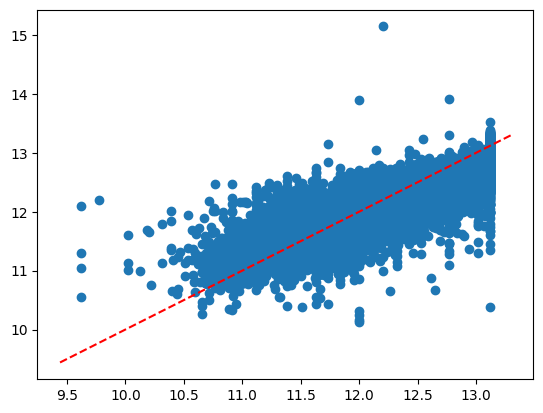

In [21]:
import matplotlib.pyplot as plt


# 在目前的圖上畫一條 y = intercept + slope * x 的紅色虛線
def abline(slope, intercept):
    axes = plt.gca()                          # 取得目前的座標軸
    x_vals = np.array(axes.get_xlim())        # x 軸範圍的兩個端點
    y_vals = intercept + slope * x_vals
    plt.plot(x_vals, y_vals, 'r--')

plt.plot(housing_labels,housing_predictions,'o')   # x：實際值；y：預測值
abline(1,0)                                        # 完美預測線 y = x

### 交叉驗證（Cross-Validation）

用訓練資料評估訓練好的模型會過度樂觀。**K 折交叉驗證**的做法：

1. 把訓練集隨機分成 $K$ 等份（這裡 $K=10$）
2. 輪流取其中 1 份當**驗證折**，用其餘 $K-1$ 份訓練
3. 得到 $K$ 個驗證誤差，取平均作為模型表現的估計

`scoring="neg_root_mean_squared_error"`：Scikit-Learn 的慣例是「**分數越大越好**」，所以誤差指標會加上負號；因此我們在前面再加一個負號把它轉回正的 RMSE。

> 💡 傳入的是整條 `lin_reg` 管線，所以每一折都會**重新 fit 前處理**，不會有資料洩漏。

In [22]:
from sklearn.model_selection import cross_val_score

# 額外程式碼 – 計算線性模型的誤差統計
lin_rmses_cv = -cross_val_score(lin_reg, housing, housing_labels,
                              scoring="neg_root_mean_squared_error", cv=10)   # 前面的負號：把 neg_RMSE 轉回 RMSE
lin_rmses_cv   # 10 折各自的 RMSE

array([0.31727112, 0.30756103, 0.30882752, 0.36163724, 0.31159759,
       0.32006093, 0.30595961, 0.32525127, 0.30623403, 0.31234581])

In [23]:
np.mean(lin_rmses_cv)   # 10 折的平均 RMSE（約 0.3177，略高於訓練集上的 0.3128）

np.float64(0.31767461513922635)

> 📌 交叉驗證的 RMSE（約 0.318）略高於訓練集 RMSE（約 0.313），這個小小的差距就是「訓練誤差過度樂觀」的程度；對於只有十幾個參數的線性模型，差距不大，表示過度配適並不嚴重。

In [24]:
tmp_linear_cv_score_mean = np.mean(lin_rmses_cv)   # 存起來，最後做方法比較用

## 3.2 前向選擇（Forward Selection）

設計矩陣共有 16 個特徵，不見得每個都有用。**前向選擇**是一種**逐步變數選擇**的貪婪演算法：

```
1. 從「沒有任何變數」的空模型開始
2. 對每個尚未選入的變數，試著把它加入模型，用交叉驗證評估表現
3. 把「使表現進步最多」的變數正式加入
4. 重複 2～3，直到選滿預定的變數個數
```

`SequentialFeatureSelector` 的重要參數：

| 參數 | 本例設定 | 說明 |
|---|---|---|
| `direction` | `"forward"` | 前向（也可設為 `"backward"` 後向淘汰） |
| `scoring` | `"neg_mean_squared_error"` | 評估標準：負的 MSE（越大越好） |
| `cv` | 10 | 每個候選模型都用 10 折交叉驗證評估 |
| `n_features_to_select` | 未設定（預設 `"auto"`） | 預設會選出**一半**的特徵（16 個選 8 個） |

> ⚠️ **兩個小提醒**
> 1. 這裡為了方便，先用**全部訓練資料** `preprocessing.fit(housing)` 做前處理，再丟進選擇器。嚴格來說，標準化用到的統計量包含了驗證折的資料，有輕微的資料洩漏；若要完全嚴謹，應把選擇器也放進 `Pipeline`。
> 2. 這個演算法需要訓練大量的候選模型：選 8 個特徵共需評估約 $16+15+\cdots+9=100$ 個候選模型，每個又要做 10 折交叉驗證（約 1,000 次迴歸），執行需要一些時間。

In [25]:
from sklearn.feature_selection import SequentialFeatureSelector

preprocessing.fit(housing)   # 先學習前處理所需的統計量
# 轉換後再包成 DataFrame，才有欄位名稱可供後面查看選了哪些變數
housing_design = pd.DataFrame(preprocessing.transform(housing), columns = preprocessing.get_feature_names_out())


sfs = SequentialFeatureSelector(LinearRegression(), scoring = "neg_mean_squared_error", direction = "forward", cv =10);
sfs.fit(housing_design, housing_labels);   # 執行前向選擇

全部 16 個候選特徵：

In [26]:
housing_design.columns   # 全部候選特徵的名稱

Index(['bedrooms__ratio', 'rooms_per_house__ratio', 'people_per_house__ratio',
       'log__total_bedrooms', 'log__total_rooms', 'log__population',
       'log__households', 'log__median_income',
       'cat__ocean_proximity_<1H OCEAN', 'cat__ocean_proximity_INLAND',
       'cat__ocean_proximity_ISLAND', 'cat__ocean_proximity_NEAR BAY',
       'cat__ocean_proximity_NEAR OCEAN', 'remainder__longitude',
       'remainder__latitude', 'remainder__housing_median_age'],
      dtype='object')

前向選擇最後選出的 8 個特徵：

In [27]:
sfs.get_feature_names_out()   # 被選中的特徵

array(['bedrooms__ratio', 'rooms_per_house__ratio', 'log__total_bedrooms',
       'log__population', 'log__households', 'log__median_income',
       'cat__ocean_proximity_INLAND', 'remainder__housing_median_age'],
      dtype=object)

> 🔍 **觀察**：被選中的包含 `log__median_income`（收入，最重要的變數）、`cat__ocean_proximity_INLAND`（是否內陸）等，但經緯度（`remainder__longitude`、`remainder__latitude`）卻**沒有被選到**。這是因為前向選擇是**貪婪**的：它每一步只看「當下」的最佳選擇，不保證找到全域最佳的特徵組合。

In [28]:
housing_design_forward = sfs.transform(housing_design)   # 只保留被選中的欄位

以選出的 8 個特徵重新訓練一個一般的線性迴歸，並計算預測值：

In [29]:
lin_reg_forward = LinearRegression()
lin_reg_forward.fit(housing_design_forward, housing_labels)

housing_predictions_forward = lin_reg_forward.predict(housing_design_forward)

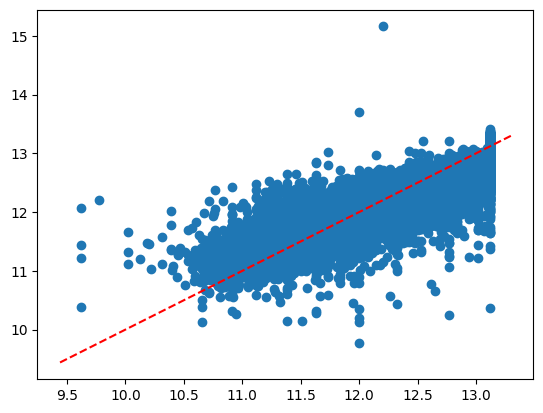

In [30]:
plt.plot(housing_labels,housing_predictions_forward,'o')   # 實際值 vs. 預測值
abline(1,0)                                                # 完美預測線

In [31]:
lin_rmse_forward = np.sqrt(mean_squared_error(housing_labels, housing_predictions_forward))   # 訓練集 RMSE
lin_rmse_forward

np.float64(0.3238890254417776)

In [32]:
# 10 折交叉驗證 RMSE（注意：選擇變數時已經用過一次 CV，這裡的估計略偏樂觀）
lin_rmse_forward_cv = -cross_val_score(lin_reg_forward, housing_design_forward, housing_labels,
                              scoring="neg_root_mean_squared_error", cv=10)

In [33]:
np.mean(lin_rmse_forward_cv)   # 平均 RMSE

np.float64(0.324848194067944)

In [34]:
tmp_linear_forward_cv_score_mean = np.mean(lin_rmse_forward_cv)   # 存起來，最後比較用

> 📌 前向選擇的 RMSE（約 0.325）**比使用全部 16 個特徵（約 0.318）還差**。可見丟掉一半變數是有代價的；如果 `n_features_to_select` 設得更大，或改用 `tol` 參數讓演算法在進步幅度很小時才停止，結果可能會不同。

## 3.3 Lasso

**Lasso**（Least Absolute Shrinkage and Selection Operator）在最小平方法上加入 **L1 懲罰項**：

$$
\hat{\boldsymbol\beta}^{\text{lasso}}=\arg\min_{\boldsymbol\beta}\ \frac{1}{2n}\sum_{i=1}^n\left(y_i-\mathbf{x}_i^\top\boldsymbol\beta\right)^2+\alpha\sum_{j=1}^p|\beta_j|
$$

- $\alpha\ge0$ 為**懲罰強度**：$\alpha=0$ 即為 OLS；$\alpha$ 越大，係數被壓得越小
- L1 懲罰的特性：會把不重要變數的係數**精確壓成 0**，因此同時完成「**係數收縮**」與「**變數選擇**」
- 因為懲罰項與係數大小有關，**特徵必須先標準化**，否則尺度大的變數會被不公平地對待（本講義的前處理已標準化）

### 如何決定 $\alpha$？—— `LassoCV`

`LassoCV` 會自動產生一組由大到小的 $\alpha$ 候選值，對每個 $\alpha$ 做 10 折交叉驗證，並挑出**交叉驗證 MSE 最小**的那個。

In [35]:
from sklearn.linear_model import LassoCV


model_lasso = LassoCV(cv=10, random_state=0)       # 10 折交叉驗證，自動選擇最佳的 alpha
model_lasso.fit(housing_design, housing_labels)
model_lasso.coef_                                  # 各特徵的估計係數：值為 0 代表該變數被剔除

array([ 0.05314573,  0.03343465,  0.02571035,  0.        ,  0.        ,
       -0.29795611,  0.31399464,  0.33933989,  0.02722414, -0.27068268,
        0.        ,  0.        , -0.        , -0.27080359, -0.28785474,
        0.03279758])

In [36]:
sum(model_lasso.coef_!=0)   # 係數不為 0 的變數個數（16 個中保留了 11 個）

np.int64(11)

In [37]:
housing_design.columns[model_lasso.coef_!=0]   # 被 Lasso 保留的變數名稱

Index(['bedrooms__ratio', 'rooms_per_house__ratio', 'people_per_house__ratio',
       'log__population', 'log__households', 'log__median_income',
       'cat__ocean_proximity_<1H OCEAN', 'cat__ocean_proximity_INLAND',
       'remainder__longitude', 'remainder__latitude',
       'remainder__housing_median_age'],
      dtype='object')

> 🔍 **與前向選擇比較**：Lasso 保留了經緯度與 `<1H OCEAN`，卻丟掉了 `log__total_bedrooms`、`log__total_rooms`。這兩個變數與其他特徵（如 `log__households`、`log__population`）**高度相關**（多重共線性），Lasso 傾向在一組高度相關的變數中只留下其中幾個。
>
> 另外，`log__population`（−0.298）與 `log__households`（+0.314）的係數幾乎等大反號，這是共線性下常見的現象：**單看個別係數的正負號與大小要很小心，不要過度解讀**。

### 交叉驗證 MSE 隨 $\alpha$ 的變化

- `alphas_`：`LassoCV` 試過的 $\alpha$ 值
- `mse_path_`：每個 $\alpha$ 在每一折上的 MSE，形狀為 `(α 個數, 折數)`；對折數取平均（`axis=1`）得到各 $\alpha$ 的 CV MSE
- 橘點（圓點）標示被選中的最佳 $\alpha$（`alpha_`）

典型的曲線是「**U 型**」：$\alpha$ 太小 → 變異大（過度配適）；$\alpha$ 太大 → 偏誤大（欠配適）。

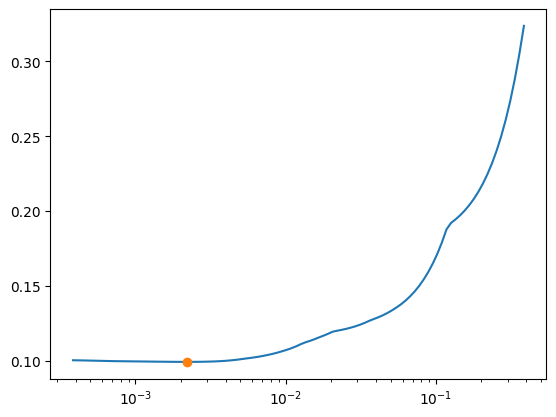

In [38]:
plt.plot(model_lasso.alphas_,model_lasso.mse_path_.mean(axis=1))    # 各 alpha 的 10 折平均 MSE
plt.plot(model_lasso.alpha_,model_lasso.mse_path_.mean(axis=1)[model_lasso.alphas_==model_lasso.alpha_],'o')   # 標出最佳 alpha
plt.xscale('log')   # alpha 跨越多個數量級，x 軸用對數刻度

把前處理與 `LassoCV` 串成完整的管線，並在訓練集上預測：

In [39]:
model_lasso_all = make_pipeline(preprocessing, model_lasso)   # 前處理 → LassoCV
model_lasso_all.fit(housing, housing_labels)

housing_predictions_lasso = model_lasso_all.predict(housing)

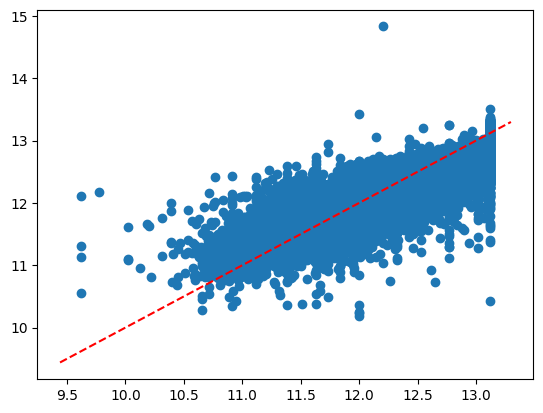

In [40]:
plt.plot(housing_labels,housing_predictions_lasso,'o')   # 實際值 vs. 預測值
abline(1,0)

最佳 $\alpha$ 對應的交叉驗證 RMSE：先對各折的 MSE **取平均**、**最後再開根號**。

> 💡 回想上一份講義：RMSE 要「先平均 MSE、再開根號」，不要先各折開根號再平均。所以這裡的 0.3152 與前面用 `cross_val_score` 對「各折 RMSE 取平均」的算法在定義上略有差異（差距很小）。

In [41]:
# 取出最佳 alpha 對應的各折 MSE 平均值，再開根號 → CV RMSE
np.sqrt(model_lasso.mse_path_.mean(axis=1)[model_lasso.alphas_==model_lasso.alpha_][0])

np.float64(0.31515175212105)

In [42]:
tmp_linear_lasso_cv_score_mean = np.sqrt(model_lasso.mse_path_.mean(axis=1)[model_lasso.alphas_==model_lasso.alpha_][0])

## 3.4 三種方法的比較（交叉驗證 RMSE，越小越好）

In [43]:
all_methods = ["Linear","Linear(Forward)","Linear(LASSO)"]
all_rmse_cv = [tmp_linear_cv_score_mean, tmp_linear_forward_cv_score_mean, tmp_linear_lasso_cv_score_mean]
pd.DataFrame({"method": all_methods,"RMSE": all_rmse_cv})

,method,RMSE
0,Linear,0.317675
1,Linear(Forward),0.324848
2,Linear(LASSO),0.315152


| 方法 | CV RMSE | 說明 |
|---|---|---|
| Linear（全部 16 個變數） | 0.3177 | 基準 |
| Linear（前向選擇 8 個變數） | 0.3248 | 最差：丟掉太多資訊 |
| Linear（Lasso，保留 11 個變數） | **0.3152** | 最好：用懲罰項溫和地收縮，同時剔除不重要變數 |

### 解讀與提醒

1. 三者差距很小（約 0.01），在實務上幾乎無差別；Lasso 的優勢在於**用更少的變數達到相同或稍好的預測**，模型更精簡、容易解釋。
2. ⚠️ **三個數字並非完全公平的比較**：
   - Lasso 的 CV RMSE 是「在 $\alpha$ 候選值中挑出最小者」，存在**選擇偏誤**（樂觀）
   - 前向選擇與 Lasso 的 CV 都是在「已對全部訓練資料做過前處理」的設計矩陣上進行，有輕微洩漏
   - 嚴謹的做法是 **巢狀交叉驗證**（nested CV），或最後用一直沒碰過的**測試集**做最終評估
3. 本講義全程**沒有使用** `strat_test_set`。測試集只應在所有模型選擇都完成後，**使用一次**作為最終的泛化能力估計。

---
# Part 2：分類 —— MNIST 手寫數字辨識

接下來把同樣的思維（基準模型 vs. 帶 L1 懲罰的模型，並用交叉驗證比較）搬到**多類別分類**問題。

## 4. 環境設定（Setup）

> 以下是 Part 2 所需的環境檢查與繪圖設定。

本專案需要 Python 3.7 以上版本：

In [44]:
import sys

assert sys.version_info >= (3, 7)   # 不符合時會丟出 AssertionError

同時需要 Scikit-Learn 1.0.1 以上版本：

In [45]:
from packaging import version
import sklearn

assert version.parse(sklearn.__version__) >= version.parse("1.0.1")

和前面的章節一樣，先設定預設字體大小，讓圖表更清楚：

In [46]:
import matplotlib.pyplot as plt

plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

建立 `images/classification` 資料夾（若尚未存在），並**重新定義** `save_fig()`（改存到新資料夾；會覆蓋 Part 1 的同名函式）：

In [47]:
from pathlib import Path

IMAGES_PATH = Path() / "images" / "classification"
IMAGES_PATH.mkdir(parents=True, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=300):
    path = IMAGES_PATH / f"{fig_id}.{fig_extension}"
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

# 5. MNIST 資料集

MNIST 是機器學習的「Hello World」：70,000 張 $28\times28$ 像素的手寫數字灰階影像（0～9）。每張影像攤平成 $28\times28=784$ 維的向量，每個元素是 0～255 的像素亮度。

`fetch_openml` 從 OpenML 網站下載資料；`as_frame=False` 表示以 NumPy 陣列（而非 DataFrame）回傳。

In [48]:
from sklearn.datasets import fetch_openml
import numpy as np

mnist = fetch_openml('mnist_784', as_frame=False)   # 下載 MNIST（第一次需要網路，約數十 MB）

In [49]:
# 額外程式碼 – 內容太長，只在需要時才印出
print(mnist.DESCR)   # 資料集的完整說明

**Author**: Yann LeCun, Corinna Cortes, Christopher J.C. Burges  
**Source**: [MNIST Website](http://yann.lecun.com/exdb/mnist/) - Date unknown  
**Please cite**:  

The MNIST database of handwritten digits with 784 features, raw data available at: http://yann.lecun.com/exdb/mnist/. It can be split in a training set of the first 60,000 examples, and a test set of 10,000 examples  

It is a subset of a larger set available from NIST. The digits have been size-normalized and centered in a fixed-size image. It is a good database for people who want to try learning techniques and pattern recognition methods on real-world data while spending minimal efforts on preprocessing and formatting. The original black and white (bilevel) images from NIST were size normalized to fit in a 20x20 pixel box while preserving their aspect ratio. The resulting images contain grey levels as a result of the anti-aliasing technique used by the normalization algorithm. the images were centered in a 28x28 image b

In [50]:
mnist.keys()  # 額外程式碼 – 本講義只會用到 data 與 target

dict_keys(['data', 'target', 'frame', 'categories', 'feature_names', 'target_names', 'DESCR', 'details', 'url'])

In [51]:
X, y = mnist.data, mnist.target   # X：特徵（像素）；y：標籤（數字，但型態是「字串」）
X

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])

In [52]:
X.shape   # (70000, 784)：7 萬張影像，每張 784 個像素

(70000, 784)

In [53]:
y   # 標籤是字串 '0'～'9'，不是整數

array(['5', '0', '4', ..., '4', '5', '6'], dtype=object)

In [54]:
y.shape   # (70000,)

(70000,)

In [55]:
28 * 28   # 784，確認像素數

784

### 觀察資料

`plot_digit()` 把 784 維向量還原成 $28\times28$ 的矩陣再畫出來（`cmap="binary"`：黑白色階）。

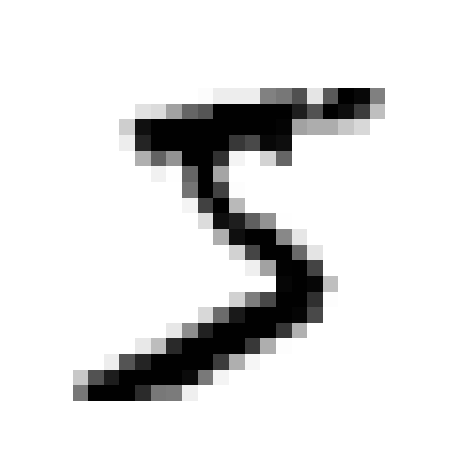

In [56]:
import matplotlib.pyplot as plt

def plot_digit(image_data):
    image = image_data.reshape(28, 28)       # 一維 784 → 二維 28x28
    plt.imshow(image, cmap="binary")         # 以黑白色階顯示
    plt.axis("off")                          # 不顯示座標軸

some_digit = X[0]                            # 第一張影像
plot_digit(some_digit)
save_fig("some_digit_plot")  # 額外程式碼：存檔
plt.show()

In [57]:
y[0]   # 第一張影像的標籤：'5'

'5'

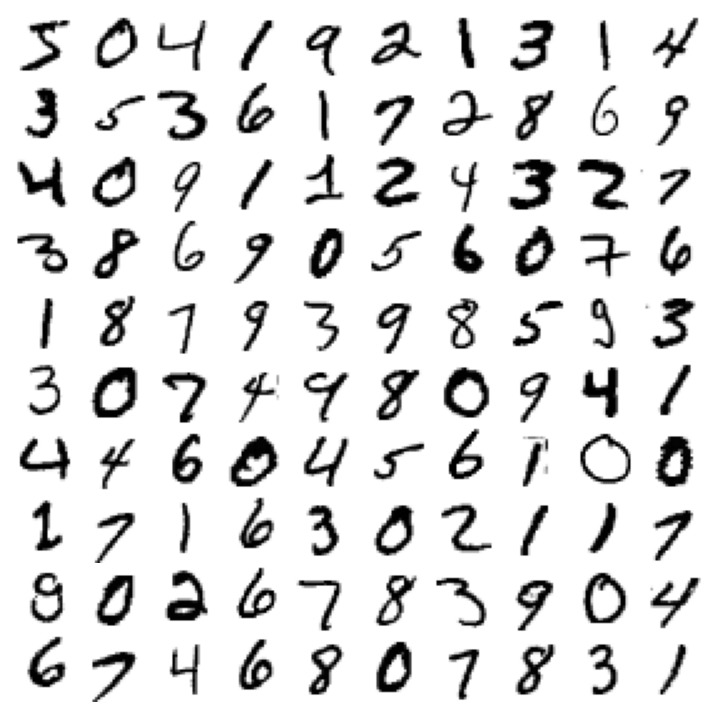

In [58]:
# 額外程式碼 – 這個 cell 產生並儲存前 100 張影像的圖（Figure 3–2）
plt.figure(figsize=(9, 9))
for idx, image_data in enumerate(X[:100]):
    plt.subplot(10, 10, idx + 1)             # 10x10 的子圖
    plot_digit(image_data)
plt.subplots_adjust(wspace=0, hspace=0)      # 子圖之間不留空隙
save_fig("more_digits_plot", tight_layout=False)
plt.show()

### 切分訓練集與測試集

MNIST 官方已經排好順序：**前 60,000 筆是訓練集、後 10,000 筆是測試集**，所以直接用切片切開即可（不需要隨機切分）。

> 💡 下面第二行被註解掉的版本只取前 5,000 筆當訓練集，可用來**加速實驗**（資料少、跑得快，但準確率會較低）。

In [59]:
X_train, X_test, y_train, y_test = X[:60000], X[60000:], y[:60000], y[60000:]
#X_train, X_test, y_train, y_test = X[:5000], X[60000:], y[:5000], y[60000:]   # 縮小版：只用 5000 筆訓練，速度較快

# 6. 訓練分類模型

## 6.1 邏輯斯迴歸（Logistic Regression）

### 二元分類

邏輯斯迴歸以 **sigmoid 函數**把線性組合轉成機率：

$$
P(y=1\mid\mathbf{x})=\sigma(\mathbf{w}^\top\mathbf{x}+b)=\frac{1}{1+e^{-(\mathbf{w}^\top\mathbf{x}+b)}}
$$

### 多類別分類（Softmax 迴歸）

對 $K$ 個類別（MNIST 為 $K=10$），每個類別有自己的一組係數 $(\mathbf{w}_k,b_k)$，機率由 **softmax** 給出：

$$
P(y=k\mid\mathbf{x})=\frac{e^{\mathbf{w}_k^\top\mathbf{x}+b_k}}{\sum_{j=1}^{K}e^{\mathbf{w}_j^\top\mathbf{x}+b_j}}
$$

訓練時最小化**交叉熵損失**（即負對數概似）：$-\sum_i\log P(y=y_i\mid\mathbf{x}_i)$。

預測時選機率最大的類別。本例共有 $10\times784$ 個權重加 10 個截距，約 7,850 個參數。

> ⚠️ **關於 `ConvergenceWarning`**：像素值範圍是 0～255，沒有縮放，`lbfgs` 最佳化器在 `max_iter=500` 內無法收斂，所以會出現警告。官方建議的做法是**縮放資料**或**增加迭代次數**。這裡為了和後面 Lasso 版本對照而保留原設定，警告不影響程式繼續執行，但結果可能不是最佳解。

In [60]:
from sklearn.linear_model import LogisticRegression
# max_iter=500：最佳化器最多迭代 500 次（預設 100，對 MNIST 不夠）
logis_class = LogisticRegression(random_state=0, max_iter=500).fit(X_train, y_train)
y_train_pred = logis_class.predict(X_train)   # 預測訓練集的類別

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


### 視覺化每個類別的係數

對每個數字類別，把它的 784 個係數 `coef_[i, :]` 還原成 $28\times28$ 影像：
- **深色（較大的正係數）**的像素：該位置有筆跡時，傾向判為這個數字
- **淺色（負係數）**的像素：該位置有筆跡時，傾向判為「不是」這個數字
- **中間灰色**：係數接近 0，該像素幾乎沒有影響

（因為 `cmap="binary"` 是「數值越大越黑」的色階，且每張圖會自動依該圖最小/最大值縮放。）

這讓我們直接「看見」模型學到的**樣板（template）**。

> 💡 原程式碼註解中的「Figure 3–2」是複製貼上留下的，此圖與該圖無關。

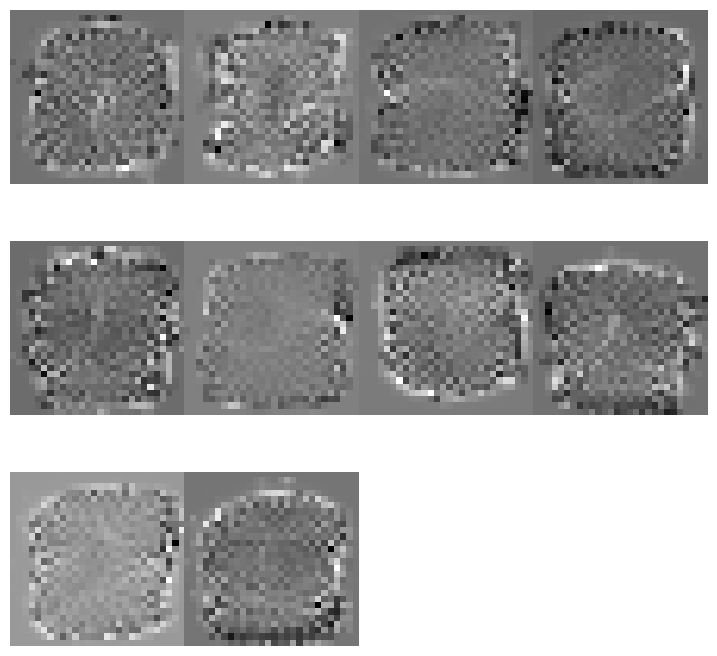

In [61]:
tmp_class_num =  logis_class.coef_.shape[0]   # 類別數（10）；coef_ 形狀為 (10, 784)
# 額外程式碼 – 把每個類別的係數畫成 28x28 的影像
plt.figure(figsize=(9, 9))
for i in range(tmp_class_num):
    plt.subplot(3, 4, i + 1)                  # 3x4 的子圖版面，放 10 張
    plot_digit(logis_class.coef_[i,:])
plt.subplots_adjust(wspace=0, hspace=0)
plt.show()

### 混淆矩陣（Confusion Matrix）

- **列**：真實類別；**行**：預測類別
- **對角線**：預測正確的個數；**非對角線**：各種誤判（例如把 4 誤判為 9）

先看**訓練集**上的結果：

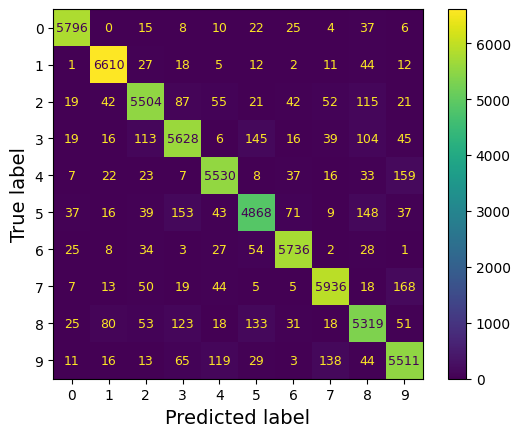

In [62]:
from sklearn.metrics import ConfusionMatrixDisplay

plt.rc('font', size=9)  # 額外程式碼 – 把字體縮小，避免 10x10 的格子擠在一起
ConfusionMatrixDisplay.from_predictions(y_train, y_train_pred)
plt.show()

In [63]:
np.mean(y_train==y_train_pred)   # 訓練集準確率：約 94.06%

np.float64(0.9406333333333333)

### 交叉驗證的預測

訓練集準確率高達 94%，但這是「用答案考試」的結果。用 **3 折交叉驗證**（`cross_val_predict`）取得**每一筆資料在「沒被用來訓練」的情況下的預測**，更能反映真實的泛化能力。

> ⏱️ 需要訓練 3 次模型，會花一些時間。

In [64]:
from sklearn.model_selection import cross_val_predict
# 每一筆資料的預測都來自「沒看過這筆資料」的模型
y_train_cv_pred = cross_val_predict(logis_class, X_train, y_train, cv=3)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

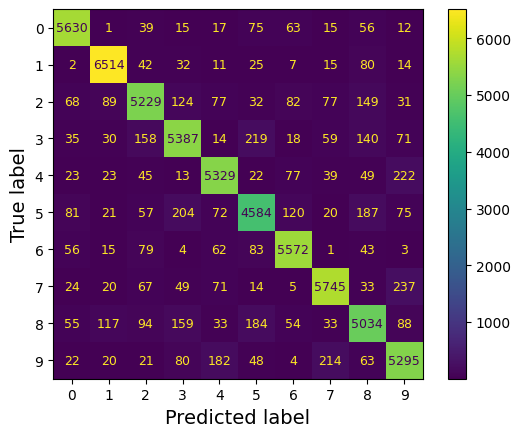

In [65]:
plt.rc('font', size=9)  # 額外程式碼 – 縮小字體
ConfusionMatrixDisplay.from_predictions(y_train, y_train_cv_pred)   # 交叉驗證預測的混淆矩陣
plt.show()

In [66]:
np.mean(y_train==y_train_cv_pred)   # 交叉驗證準確率：約 90.53%

np.float64(0.9053166666666667)

> 📌 **訓練準確率 94.06% vs. 交叉驗證準確率 90.53%**：差距約 3.5 個百分點，代表模型有一定程度的**過度配適**（記住了訓練集的特性）。這也是我們需要**正則化**（下一節的 L1 懲罰）的原因。

`cross_val_score` 直接回傳每一折的準確率（`scoring="accuracy"`）。因為三折大小相同（各 20,000 筆），它們的平均就等於上面 `cross_val_predict` 算出來的整體準確率：

In [67]:
from sklearn.model_selection import cross_val_score

# 分類問題的 cross_val_score 預設會使用「分層」K 折，讓每折的類別比例相近
tmp_cv_score = cross_val_score(logis_class, X_train, y_train, cv=3, scoring="accuracy")
tmp_cv_score   # 三折各自的準確率

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

array([0.9044 , 0.9051 , 0.90645])

In [68]:
tmp_logistic_cv_score_mean = np.mean(tmp_cv_score)   # 平均準確率，存起來最後比較用

## 6.2 帶 Lasso（L1 懲罰）的邏輯斯迴歸

與迴歸中的 Lasso 相同，對損失函數加上 L1 懲罰，讓不重要的像素係數變成 0。Scikit-Learn 中的目標函數為：

$$
\min_{\mathbf{w},b}\ \|\mathbf{w}\|_1+C\sum_{i=1}^n\ell\big(y_i,\ \hat p_i\big)
$$

其中 $\ell$ 為交叉熵損失。注意 **$C$ 是「懲罰強度的倒數」**：

| $C$ | 懲罰 | 模型 |
|---|---|---|
| 小 | 強 | 大量係數被壓為 0，模型簡單（可能欠配適） |
| 大 | 弱 | 係數幾乎不受限，趨近一般邏輯斯迴歸（可能過度配適） |

### 設定說明

- `LogisticRegressionCV`：自動用交叉驗證從一組 $C$ 候選值（預設為 $10^{-4}\sim10^{4}$ 之間的 10 個值）中挑出最佳者
- `penalty='l1'`：使用 L1 懲罰；`solver='saga'`：支援 L1 懲罰的最佳化器，適合大型資料集
- `scoring='accuracy'`：以準確率作為挑選 $C$ 的標準；`cv=3`：3 折交叉驗證；`n_jobs=5`：平行使用 5 個 CPU 核心加速
- **必須先標準化像素**（`StandardScaler`）：L1 懲罰對尺度敏感，`saga` 在未縮放的資料上也很難收斂
- `X_train.astype("float64")`：先轉成浮點數再標準化

> ⏱️ **這個 cell 執行時間較長**（60,000 筆 × 784 維 × 10 個候選 $C$ × 3 折），可能需要數分鐘。出現 `ConvergenceWarning` 代表 `saga` 在預設的 100 次迭代內尚未完全收斂，在這個示範中可以接受。

In [69]:
from sklearn.linear_model import LogisticRegressionCV
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train.astype("float64"))   # 標準化每個像素（平均 0、標準差 1）

# 以 3 折交叉驗證，在 10 個 C 值中挑出準確率最高者；再用最佳 C 以全部訓練資料重新訓練
logis_class_lasso = LogisticRegressionCV(random_state=0, n_jobs = 5, penalty = 'l1', solver = 'saga', cv=3, scoring='accuracy').fit(X_train_scaled, y_train)
y_train_pred = logis_class_lasso.predict(X_train_scaled)   # 預測訓練集（注意：輸入必須是標準化後的資料）

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


### 視覺化 Lasso 版本的係數

與一般邏輯斯迴歸相比，**中間灰色（係數恰好為 0）的區域會明顯變多**，代表 L1 懲罰把許多不重要的像素（例如影像邊緣、幾乎從不出現筆跡的位置）剔除了。

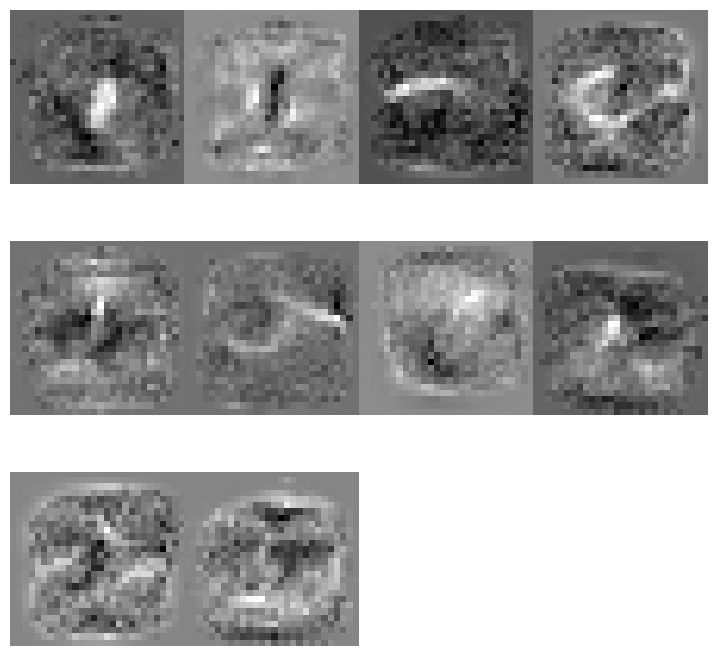

In [70]:
tmp_class_num =  logis_class_lasso.coef_.shape[0]   # 類別數（10）
# 額外程式碼 – 畫出各類別的係數影像
plt.figure(figsize=(9, 9))
for i in range(tmp_class_num):
    plt.subplot(3, 4, i + 1)
    plot_digit(logis_class_lasso.coef_[i,:])
plt.subplots_adjust(wspace=0, hspace=0)
plt.show()

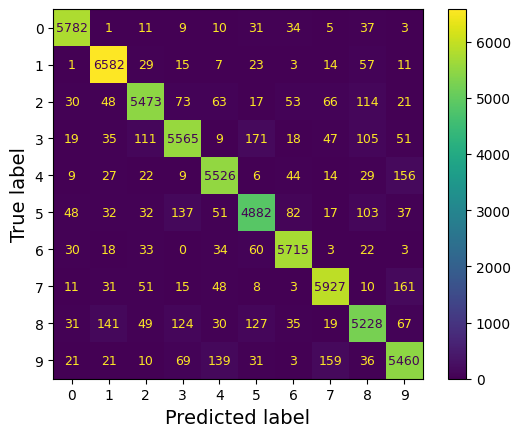

In [71]:
plt.rc('font', size=9)  # 額外程式碼 – 縮小字體
ConfusionMatrixDisplay.from_predictions(y_train, y_train_pred)   # 訓練集的混淆矩陣
plt.show()

In [72]:
np.mean(y_train==y_train_pred)   # 訓練集準確率：約 93.57%（略低於未懲罰的 94.06%，這是正則化的預期效果）

np.float64(0.9356666666666666)

### 取出交叉驗證的準確率

`scores_` 是一個字典：鍵是類別、值是形狀為「折數 × $C$ 候選值個數」的準確率陣列。以下對折數取平均，再對各類別取平均，得到每個 $C$ 值的 CV 準確率。

> 💡 在多類別（multinomial）設定下，各類別對應的分數陣列內容相同，所以對類別取平均不會改變結果；只是程式碼寫得比較繁瑣。

In [73]:
cv_score_avg=dict()
keys_list = logis_class_lasso.scores_.keys()                # 各類別的鍵
for tmp_key in keys_list:
    cv_score_avg[tmp_key] = logis_class_lasso.scores_[tmp_key].mean(axis=0)   # 對 3 折取平均
#logis_class_lasso.scores_
cv_score_avg2 = np.array(list(cv_score_avg.values())).mean(axis=0)            # 再對各類別取平均

### 準確率隨 $C$ 的變化

`Cs_` 是 `LogisticRegressionCV` 試過的 $C$ 候選值。曲線通常是先上升（$C$ 太小時懲罰過強，欠配適）、再趨於平緩或略降（$C$ 太大時過度配適）。

> 💡 $C$ 跨越多個數量級，加上 `plt.xscale('log')` 會更容易觀察。

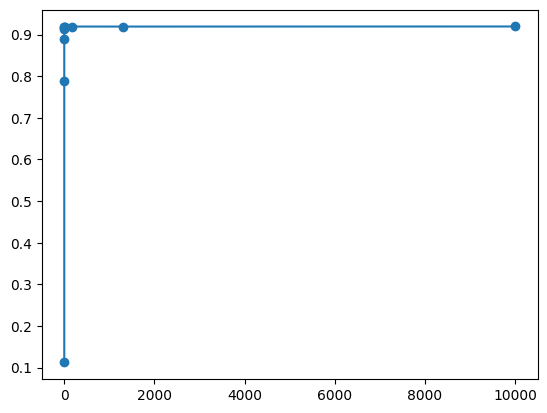

In [74]:
plt.plot(logis_class_lasso.Cs_,cv_score_avg2,'o-')   # x：C 候選值；y：對應的 CV 準確率

In [75]:
cv_score_avg2[np.where(cv_score_avg2==np.max(cv_score_avg2))[0]]   # 最高的 CV 準確率：約 91.95%

array([0.91953333])

In [76]:
tmp_logistic_lasso_cv_score_mean = cv_score_avg2[np.where(cv_score_avg2==np.max(cv_score_avg2))[0]]

## 6.3 兩種分類模型的比較（3 折交叉驗證準確率，越大越好）

In [77]:
all_methods = ["Logistic","Logistic(LASSO)"]
all_rmse_cv = [tmp_logistic_cv_score_mean, tmp_logistic_lasso_cv_score_mean[0]]   # 注意：這裡存的是「準確率」，變數名稱沿用先前的 all_rmse_cv
pd.DataFrame({"method": all_methods,"Accuracy": all_rmse_cv})

,method,Accuracy
0,Logistic,0.905317
1,Logistic(LASSO),[0.9195333333333335]


> ❓ **為什麼第二列的準確率顯示成 `[0.9195...]`（帶中括號），而不是單純的數字？**
> 因為 `tmp_logistic_lasso_cv_score_mean[0]` 取出的仍是一個「長度為 1 的陣列」，而不是純量。這多半是新版 Scikit-Learn 的 `scores_` 多了一個 `l1_ratio` 維度所致。若想讓表格顯示乾淨的數字，可以改用：
>
> ```python
> float(np.max(cv_score_avg2))   # 直接取最大值，轉成純量
> ```

| 方法 | 3 折 CV 準確率 |
|---|---|
| Logistic（無懲罰，未縮放，`lbfgs`） | 90.53% |
| Logistic + Lasso（L1，標準化，`saga`） | **91.95%** |

> ⚠️ **公平性提醒**：兩者的前處理不同（Lasso 版本做了標準化、一般版本沒有），所以 1.4 個百分點的改進**不能全部歸因於 L1 懲罰**；一部分可能來自標準化。若要嚴格比較，應該讓兩個模型使用相同的前處理。

# 7. 重點整理與課後練習

## 重點整理

1. **完整流程**：取得資料 → 分層抽樣切出測試集 → 前處理（填補、編碼、縮放、轉換）→ 建模 → 交叉驗證評估 → 最後才用測試集。
2. **避免資料洩漏**：所有「學習統計量」的步驟（填補、標準化、編碼）都只能用**訓練資料**；用 `Pipeline` / `ColumnTransformer` 把它們與模型包在一起，交叉驗證時才不會洩漏。
3. **訓練誤差過度樂觀**：訓練 RMSE 0.313 vs. CV RMSE 0.318（迴歸）、訓練準確率 94.06% vs. CV 準確率 90.53%（分類）。評估一律以交叉驗證或測試集為準。
4. **處理變數過多的三種策略**

   | 方法 | 機制 | 特色 |
   |---|---|---|
   | 全部變數 | 不處理 | 基準；變數多時易過度配適 |
   | 前向選擇 | 逐步加入變數（貪婪） | 結果是「選或不選」；不保證全域最佳；計算量大 |
   | Lasso | L1 懲罰，係數可壓成 0 | 收縮 + 選擇一次完成；需要標準化與選 $\alpha$（或 $C$） |

5. **轉換之後，解讀也要跟著轉換**：目標變數取對數後，預測值與 RMSE 都在對數尺度，需 `np.exp()` 還原。
6. 評估指標的聚合要小心：RMSE 應「先平均 MSE 再開根號」。

## 課後練習

1. 把 3.1 節的 `LinearRegression` 換成 `Ridge`（L2 懲罰）與 `ElasticNetCV`，比較它們與 Lasso 的 CV RMSE 與係數。
2. 在前向選擇中把 `n_features_to_select` 分別設為 4、8、12，畫出 CV RMSE 對變數個數的曲線。
3. 把 `SequentialFeatureSelector` 與 `LinearRegression` 放進同一個 `Pipeline` 再做交叉驗證，與目前的結果相比，結果是否有變？（提示：嚴謹地處理資料洩漏。）
4. 將 `direction` 改為 `"backward"`，比較前向與後向選擇選出的變數是否相同。
5. 在 MNIST 一般邏輯斯迴歸中，先把像素除以 255 縮放到 $[0,1]$，觀察 `ConvergenceWarning` 是否消失，準確率是否改變。
6. 讓 MNIST 的一般邏輯斯迴歸與 Lasso 版本使用**相同的前處理**（都標準化），重新比較兩者的準確率，並計算被 Lasso 設為 0 的係數比例：`np.mean(logis_class_lasso.coef_ == 0)`。
7. 在 `plt.plot(logis_class_lasso.Cs_, cv_score_avg2, 'o-')` 加上 `plt.xscale('log')`，說明曲線形狀。
8. 完成所有模型選擇後，用 `strat_test_set` 計算 Lasso 迴歸模型的**測試集 RMSE**，並把它還原成美元尺度後解讀。